# Monte Carlo (MC) Methods

## MC Integrations with Uniform Probability Densities

Given a function $f(x)$ on $[a, b]$, we draw $N$ uniform random samples $X_1, \dots, X_N \sim \text{Uniform}(a, b)$ with probability density $p_X(x) = \frac{1}{b-a}$.

1. **Sample Mean Estimator:**
   $$\langle f \rangle = \frac{1}{N} \sum_{j=1}^N f(X_j), \quad \langle f^2 \rangle = \frac{1}{N} \sum_{j=1}^N f(X_j)^2$$
   By the Law of Large Numbers, as $N \to \infty$, the integral is approximated by:
   $$I = \int_a^b f(s)ds \approx (b - a)\langle f \rangle$$

2. **Error Estimation via Central Limit Theorem (CLT):**
   For large $N$, the sample mean $\langle f \rangle$ follows a normal distribution centered at $E(f(X))$ with variance $\frac{V(f(X))}{N}$.
   * **Sample Variance of $f$:** $V(f(X)) \approx \langle f^2 \rangle - \langle f \rangle^2$
   * **Standard Error of $\langle f \rangle$:** $\sigma_{\langle f \rangle} = \sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$
   * **Standard Error of the Integral $I$:** $\sigma_I = (b - a)\sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$

Key takeaway: The Monte Carlo integration error decreases at a rate of $\mathcal{O}(1/\sqrt{N})$, regardless of the number of dimensions!

In [13]:
# a visual verification of the 1/√N convergence rate:

import numpy as np
import matplotlib.pyplot as plt

def monte_carlo_integrate(f, a, b, N, seed=42):
    """
    Approximates the integral of f(x) from a to b using N uniform samples.
    Returns the integral estimate and the CLT standard error.
    """
    rng = np.random.default_rng(seed) # Use a random number generator for reproducibility
    
    # 1. Draw N uniform samples in [a, b]
    X = rng.uniform(a, b, N) # Draw N uniform samples in [a, b]
    
    # 2. Evaluate Y_j = f(X_j)
    Y = f(X)
    
    # 3. Compute <f> and <f^2>
    f_mean = np.mean(Y)
    f_sq_mean = np.mean(Y**2)
    
    # 4. Estimate variance V(Y) = <f^2> - <f>^2
    var_f = f_sq_mean - f_mean**2
    
    # 5. Compute integral estimate and standard error scaled by (b - a)
    integral_est = (b - a) * f_mean
    error_est = (b - a) * np.sqrt(var_f / N) # CLT standard error = sqrt(V(Y)/N)
    
    return integral_est, error_est

# Example: Integrate f(x) = sin(x) from 0 to pi (Exact answer = 2.0)
f = np.sin
a, b = 0, np.pi
exact_val = 2.0

N = 10_000
est, err = monte_carlo_integrate(f, a, b, N)
actual_err = abs(est - exact_val)

print(f"Monte Carlo Estimate (N={N}): {est:.6f}")
print(f"Exact Integral Value         : {exact_val:.6f}")
print(f"CLT Estimated Error (1 sigma): ±{err:.6f}")
print(f"Actual Absolute Error        : {actual_err:.6f}")

Monte Carlo Estimate (N=10000): 2.003473
Exact Integral Value         : 2.000000
CLT Estimated Error (1 sigma): ±0.009663
Actual Absolute Error        : 0.003473


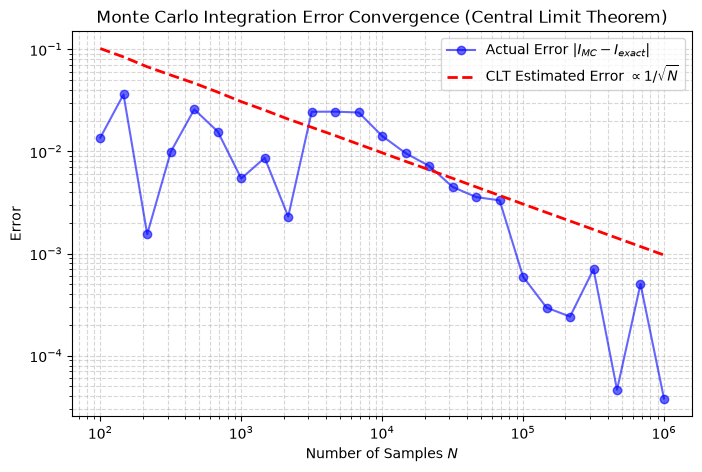

In [17]:
# --- Plot Error Convergence vs N ---
N_values = np.logspace(2, 6, 25, dtype=int) # arr = np.logspace(0, 3, num=4) - Output: [   1.   10.  100. 1000.]
actual_errors = []
clt_errors = []

for n in N_values:
    integral_n, err_n = monte_carlo_integrate(f, a, b, n, seed=101)
    actual_errors.append(abs(integral_n - exact_val))
    clt_errors.append(err_n)

plt.figure(figsize=(8, 5))
plt.loglog(N_values, actual_errors, 'o-', alpha=0.6, label='Actual Error $|I_{MC} - I_{exact}|$', color='blue')
plt.loglog(N_values, clt_errors, 'r--', linewidth=2, label=r'CLT Estimated Error $\propto 1/\sqrt{N}$')
plt.xlabel('Number of Samples $N$')
plt.ylabel('Error')
plt.title('Monte Carlo Integration Error Convergence (Central Limit Theorem)')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

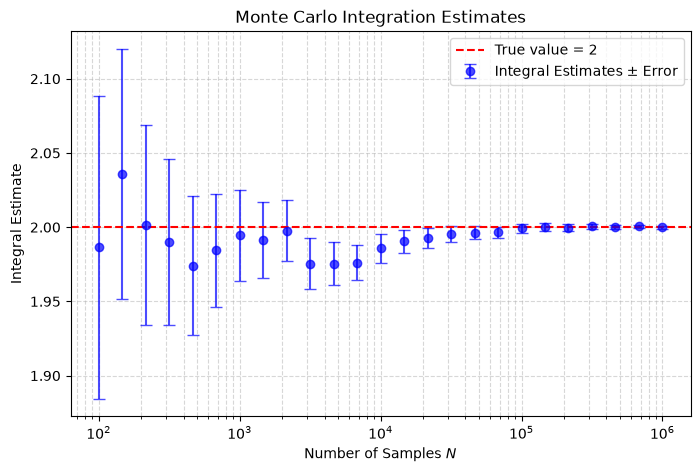

In [16]:
# --- Plot Integral estimates vs N ---
N_values = np.logspace(2, 6, 25, dtype=int)
integral_estimates = []
integral_errors = []

for n in N_values:
    integral_n, err_n = monte_carlo_integrate(f, a, b, n, seed=101)
    integral_estimates.append(integral_n)
    integral_errors.append(err_n)

plt.figure(figsize=(8, 5))
plt.errorbar(
    N_values,
    integral_estimates,
    yerr=integral_errors,
    fmt='o',
    linestyle='none',  # Do not connect the points
    capsize=4,
    alpha=0.7,
    color='blue',
    label='Integral Estimates ± Error',
)
plt.axhline(2, color='red', linestyle='--', linewidth=1.5, label='True value = 2')

plt.xscale('log')
plt.xlabel('Number of Samples $N$')
plt.ylabel('Integral Estimate')
plt.title('Monte Carlo Integration Estimates')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.5)
plt.show()

## MC Integration with Non-Uniform Probability Densities
When an integral over a $D$-dimensional volume $\mathcal{V}$ is weighted by a normalized non uniform probability density $p(\vec{x})$ (such that $\int_{\mathcal{V}} p(\vec{x}) d^D x = 1$), we draw $N$ independent random vectors $\vec{x}_1, \dots, \vec{x}_N \sim p(\vec{x})$:

$$\int_{\mathcal{V}} p(\vec{x}) f(\vec{x}) d^D x \approx \langle f \rangle \pm \sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$$

where:
$$\langle f \rangle \equiv \frac{1}{N} \sum_{i=1}^N f(\vec{x}_i), \qquad \langle f^2 \rangle \equiv \frac{1}{N} \sum_{i=1}^N f(\vec{x}_i)^2$$

* **Justification:** The **Law of Large Numbers** guarantees convergence to the exact integral as $N \to \infty$, and the **Central Limit Theorem** guarantees that the estimate is Gaussian-distributed with standard error $\propto 1/\sqrt{N}$ (independent of dimension $D$).
* **Note on Uniform Volume $\mathcal{V}$:** If we want to integrate $\int_{\mathcal{V}}  p(\vec{x}) f(\vec{x}) d^D x$ using uniform sampling over a volume $V = \int_{\mathcal{V}} d^D x$, then $p(\vec{x}) = 1/V$, which means we get:

$$\int_{\mathcal{V}} f(\vec{x}) d^D x \approx V \langle f \rangle \pm V \sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$$

### Pseudorandom Number Generators (PRNGs)
* Computers are deterministic and generate **pseudorandom** sequences using modulus operations, bit shifting, and shuffling.
* **Mersenne Twister (`MT19937`):** A fast, high-quality PRNG with a period of $2^{19937}-1$ that passes the Diehard test suite.

The code below demonstrates:

1. Using the Mersenne Twister (MT19937) explicitly in NumPy.   
2. 1D Non-Uniform Monte Carlo Integration (sampling from an exponential distribution $p_X(x)= e^{-x}, x \in [0,∞))$.   
3. D-Dimensional Monte Carlo Integration (integrating a 5D function over a 5D Gaussian distribution $p(x)$).

In [ ]:
# Initialize NumPy's random generator explicitly with the Mersenne Twister (MT19937)
bit_gen = np.random.MT19937(seed=42)
rng = np.random.Generator(bit_gen)
print(f"Using PRNG: {rng.bit_generator.__class__.__name__}\n")

Using PRNG: MT19937



In [9]:
# =====================================================================
# Example 1: Non-Uniform 1D Monte Carlo Integration
# Goal: Evaluate I = \int_0^\infty e^{-x} * cos(x) dx
# Here, p_X(x) = e^{-x} (Exponential distribution with scale=1)
#       f(x)   = cos(x)
# Exact analytical answer: 0.5
# =====================================================================
N = 100_000

# 1. Sample X_1, ..., X_N directly from p_X(x) = e^{-x}
X_exp = rng.exponential(scale=1.0, size=N) # scale = 1/lambda, where lambda is the rate parameter: e^(-lambda*x). Here, lambda = 1, so scale = 1/lambda = 1.

# 2. Apply f(x) = cos(x)
Y = np.cos(X_exp)

# 3. Compute <f>, <f^2>, and CLT uncertainty
f_mean = np.mean(Y)
f_sq_mean = np.mean(Y**2)
uncertainty = np.sqrt((f_sq_mean - f_mean**2) / N)

print("--- 1D Non-Uniform Monte Carlo (Exponential p_X) ---")
print(f"Integral: \\int_0^\\infty e^(-x) cos(x) dx")
print(f"MC Estimate : {f_mean:.6f} ± {uncertainty:.6f}")
print(f"Exact Value : 0.500000")
print(f"Actual Error: {abs(f_mean - 0.5):.6f}\n")

--- 1D Non-Uniform Monte Carlo (Exponential p_X) ---
Integral: \int_0^\infty e^(-x) cos(x) dx
MC Estimate : 0.499041 ± 0.001875
Exact Value : 0.500000
Actual Error: 0.000959



In [12]:
# =====================================================================
# Example 2: D-Dimensional Monte Carlo Integration (D = 5)
# Goal: Evaluate I = \int_{R^D} p(\vec{x}) * ||\vec{x}||^2 d^D x
# where p(\vec{x}) is the D-dimensional Standard Normal distribution:
#       p(\vec{x}) = (2*pi)^(-D/2) * exp(-||\vec{x}||^2 / 2)
# and f(\vec{x}) = x_1^2 + x_2^2 + ... + x_D^2
# Exact analytical answer: E[sum(X_i^2)] = D * 1 = 5.0
# =====================================================================
D = 5
N_dim = 100_000

# 1. Draw N independent D-dimensional vectors \vec{x}_i from standard normal p(\vec{x})
# Shape of X_vec is (N_dim, D) 
X_vec = rng.normal(loc=0.0, scale=1.0, size=(N_dim, D)) # loc=0.0 (mean), scale=1.0 (std dev) for standard normal distribution
print(f"X_vec:\n{X_vec}")

# 2. Evaluate f(\vec{x}_i) = sum of squares along each D-dimensional vector
f_vals = np.sum(X_vec**2, axis=1)

# 3. Compute <f>, <f^2>, and CLT uncertainty
f_mean_D = np.mean(f_vals)
f_sq_mean_D = np.mean(f_vals**2)
uncertainty_D = np.sqrt((f_sq_mean_D - f_mean_D**2) / N_dim)

print(f"--- {D}D Monte Carlo Integration (Multivariate Gaussian p(x)) ---")
print(f"MC Estimate : {f_mean_D:.6f} ± {uncertainty_D:.6f}")
print(f"Exact Value : {float(D):.6f}")
print(f"Actual Error: {abs(f_mean_D - D):.6f}")

X_vec:
[[-0.09620087  0.60170805  0.81783429 -1.64702718 -0.35696102]
 [-0.31857696 -1.16250237 -1.05716897 -0.48008613 -1.09849012]
 [ 1.77727812 -0.81191691 -0.18118261 -0.12807031  0.87835093]
 ...
 [-0.7030029  -1.34571191 -0.7908694  -0.49342146 -0.92946308]
 [-0.20528156 -0.53203329 -0.26114983 -0.50151195  0.29269182]
 [-2.6029967  -2.45727756 -0.80420315  0.0472284   0.54943807]]
--- 5D Monte Carlo Integration (Multivariate Gaussian p(x)) ---
MC Estimate : 4.982538 ± 0.009977
Exact Value : 5.000000
Actual Error: 0.017462


## Importance Sampling Method

Simple Monte Carlo integration ($\int_a^b f(x)dx \approx \frac{b-a}{N}\sum_{j=1}^N f(x_j)$ with uniform $x_j$) performs poorly when $f(x)$ is sharply peaked or oscillates rapidly, because the variance $V(f)$ is very large.

**Importance Sampling** reduces the variance by introducing a normalized probability density $g(x) > 0$ ($\int_a^b g(x)dx = 1$) that mimics the shape of $f(x)$, so that the ratio:
$$h(x) = \frac{f(x)}{g(x)}$$
is as close to a **flat constant** as possible.

We rewrite the integral as an expectation over the probability density $g(x)$:
$$\int_a^b f(x)dx = \int_a^b \frac{f(x)}{g(x)} g(x) dx = \int_a^b h(x) g(x) dx \approx \frac{1}{N} \sum_{j=1}^N h(x_j) \pm \sqrt{\frac{\langle h^2 \rangle - \langle h \rangle^2}{N}}$$
where the sample points $x_1, \dots, x_N$ are drawn from the probability distribution $g(x)$.

**Why it works:**
* Because $g(x)$ is large where $f(x)$ is peaked, more sample points $x_j$ are automatically placed in the important peaked regions.
* Because $h(x) = f(x)/g(x)$ is nearly flat, its variance $\langle h^2 \rangle - \langle h \rangle^2$ is much smaller than the variance of $f(x)$, yielding a drastically smaller error for the same $N$.

Exact Integral Value       : 15.607967

Simple MC Estimate         : 14.753283 ± 1.209133 (Actual err: 0.854683)
Importance Sampling Est.   : 15.626230 ± 0.264329 (Actual err: 0.018264)

Error Reduction Factor     : 4.6x smaller uncertainty!


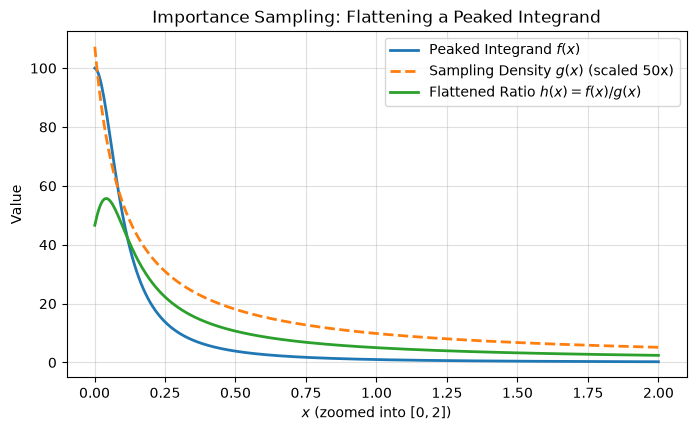

In [ ]:
# =====================================================================
# Example 3: Importance Sampling for a Sharply Peaked Integrand
# Goal: Evaluate I = \int_0^10 f(x) dx, where f(x) = 1 / (x^2 + 0.01)
# Exact analytical answer: I = 10 * arctan(100) ≈ 15.707963267
# =====================================================================

rng = np.random.default_rng(42)
N = 5_000
a, b = 0.0, 10.0

# Sharply peaked function near x = 0: f(x) = 1 / (x^2 + 0.01)

def f(x):
    return 1.0 / (x**2 + 0.01)

exact_val = 10.0 * np.arctan(100.0)

# -------------------------------------------------------------------------
# 1. Simple Monte Carlo (Uniform x_j in [a, b])
# -------------------------------------------------------------------------
x_unif = rng.uniform(a, b, N)
f_vals = (b - a) * f(x_unif)

mc_simple = np.mean(f_vals)
err_simple = np.sqrt((np.mean(f_vals**2) - mc_simple**2) / N)

# -------------------------------------------------------------------------
# 2. Importance Sampling using g(x)
# Choose a normalized probability density g(x) on [0, 10] that also peaks at 0:
# Let g(x) = C / (x + 0.1), where C = 1 / ln(101) so that \int_0^10 g(x) dx = 1
# -------------------------------------------------------------------------
norm_C = 1.0 / np.log(101.0)

def g(x):
    return norm_C / (x + 0.1)

def h(x):
    return f(x) / g(x)

# Sample x_j from g(x) using Inverse Transform Sampling:
# CDF G(x) = C * ln(10*(x + 0.1)) = u  =>  x = 0.1 * (101^u - 1)
u = rng.uniform(0.0, 1.0, N)
x_imp = 0.1 * (101.0**u - 1.0) # x sampled from g(x) using inverse transform sampling

# Evaluate h(x_j) = f(x_j) / g(x_j)
h_vals = h(x_imp)

mc_imp = np.mean(h_vals)
err_imp = np.sqrt((np.mean(h_vals**2) - mc_imp**2) / N)

print(f"Exact Integral Value       : {exact_val:.6f}\n")
print(f"Simple MC Estimate         : {mc_simple:.6f} ± {err_simple:.6f} (Actual err: {abs(mc_simple - exact_val):.6f})")
print(f"Importance Sampling Est.   : {mc_imp:.6f} ± {err_imp:.6f} (Actual err: {abs(mc_imp - exact_val):.6f})")
print(f"\nError Reduction Factor     : {err_simple / err_imp:.1f}x smaller uncertainty!")

# --- Plot f(x), g(x), and flat h(x) ---
x_grid = np.linspace(0.001, 2.0, 500)
plt.figure(figsize=(8, 4.5))
plt.plot(x_grid, f(x_grid), label='Peaked Integrand $f(x)$', lw=2)
plt.plot(x_grid, g(x_grid) * 50, '--', label='Sampling Density $g(x)$ (scaled 50x)', lw=2)
plt.plot(x_grid, h(x_grid), label='Flattened Ratio $h(x) = f(x)/g(x)$', lw=2)
plt.xlabel('$x$ (zoomed into $[0, 2]$)')
plt.ylabel('Value')
plt.title('Importance Sampling: Flattening a Peaked Integrand')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

### Generalized Theorem of MC Integration with Importance Sampling

To integrate any function $f$ over a volume $V$, we can draw $N$ random points $x_0, \dots, x_{N-1}$ from any normalized probability density $p(x)$ satisfying:
$$\int_V p \, dV = 1$$

The **Generalized Fundamental Theorem of Monte Carlo Integration** estimates the integral and its $1\sigma$ statistical error as:
$$I \equiv \int_V f \, dV = \int_V \frac{f}{p} p \, dV \approx \left\langle \frac{f}{p} \right\rangle \pm \sqrt{\frac{\langle f^2/p^2 \rangle - \langle f/p \rangle^2}{N}}$$

where the angle brackets denote arithmetic averages over the $N$ points $x_i \sim p(x)$:
$$\left\langle \frac{f}{p} \right\rangle = \frac{1}{N} \sum_{i=0}^{N-1} \frac{f(x_i)}{p(x_i)}, \qquad \left\langle \frac{f^2}{p^2} \right\rangle = \frac{1}{N} \sum_{i=0}^{N-1} \left(\frac{f(x_i)}{p(x_i)}\right)^2$$

* **Special Case (Uniform Sampling):** When points are chosen uniformly over volume $V$, the constant probability density is $p(x) = \frac{1}{V}$. Substituting $p = 1/V$ into the generalized formula factors out $V$:
  $$I \approx V \langle f \rangle \pm V \sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$$
* **Zero-Variance Ideal:** If $p(x)$ is chosen proportional to $|f(x)|$, the ratio $f(x)/p(x)$ becomes constant, making the variance $\langle f^2/p^2 \rangle - \langle f/p \rangle^2$ vanish!

In [ ]:
# =====================================================================
# Generalized Monte Carlo Integration (Importance Sampling)   
# =====================================================================

import numpy as np

def mc_generalized(f, p, sample_from_p, N):

    """
    Implements Equation: Generalized Monte Carlo Integration.
    
    Parameters:
    - f: function f(x) to integrate
    - p: normalized probability density function p(x) such that int p dV = 1
    - sample_from_p: function(N) that returns N random samples drawn from p(x)
    - N: number of sample points
    
    Returns:
    - est: integral estimate <f/p>
    - err: 1-sigma error estimate sqrt((<f^2/p^2> - <f/p>^2) / N)
    """

    # 1. Draw N samples x_0, ..., x_{N-1} from probability density p
    x = sample_from_p(N)
    
    # 2. Compute the weighted ratios w_i = f(x_i) / p(x_i)
    ratios = f(x) / p(x)
    
    # 3. Compute arithmetic means <f/p> and <f^2/p^2>
    mean_fp = np.mean(ratios) 
    mean_f2p2 = np.mean(ratios**2) 
    
    # 4. Compute 1-sigma standard error
    error = np.sqrt((mean_f2p2 - mean_fp**2) / N)
    
    return mean_fp, error


# =====================================================================
# Test Problem: Integrate f(x) = e^{-2x} on [0, 5]
# Exact value: (1 - e^{-10}) / 2 ≈ 0.4999773
# =====================================================================
rng = np.random.default_rng(42)
a, b = 0.0, 5.0
V = b - a  # 1D volume (length of interval)
N = 10_000

f = lambda x: np.exp(-2.0 * x)
exact_val = 0.5 * (1.0 - np.exp(-10.0))

# --- Case 1: Special Case of Uniform Sampling (p(x) = 1 / V) ---
p_uniform = lambda x: np.full_like(x, 1.0 / V)
sample_uniform = lambda n: rng.uniform(a, b, n)

est_unif, err_unif = mc_generalized(f, p_uniform, sample_uniform, N)

# --- Case 2: Non-Uniform Sampling (Truncated Exponential p(x) on [0, 5]) ---
# Let p(x) = C * e^{-x} on [0, 5], where C = 1 / (1 - e^{-5}) so \int_0^5 p(x)dx = 1
norm_C = 1.0 / (1.0 - np.exp(-5.0))
p_exp = lambda x: norm_C * np.exp(-x)
# Inverse transform sampling for p(x) = C * e^{-x} on [0, 5]:
sample_exp = lambda n: -np.log(1.0 - rng.uniform(0.0, 1.0, n) / norm_C)

est_imp, err_imp = mc_generalized(f, p_exp, sample_exp, N)

print(f"Exact Integral Value                  : {exact_val:.6f}\n")
print(f"1. Uniform Special Case (p = 1/V)     : {est_unif:.6f} ± {err_unif:.6f}")
print(f"2. Non-Uniform Sampling (p ~ e^{{-x}})  : {est_imp:.6f} ± {err_imp:.6f}")
print(f"\nVariance reduction factor (err_unif / err_imp): {err_unif / err_imp:.2f}x")

Exact Integral Value                  : 0.499977

1. Uniform Special Case (p = 1/V)     : 0.503304 ± 0.009997
2. Non-Uniform Sampling (p ~ e^{-x})  : 0.497081 ± 0.002850

Variance reduction factor (err_unif / err_imp): 3.51x


### Inverse Transform Importance Sampling

Random number generators produce uniform deviates $U \sim \text{Uniform}(0, 1)$ with probability density $p_U(u) = 1$ for $0 \le u \le 1$. To sample a random variable $Y$ with a desired target probability density $p_Y(y)$, we apply a strictly increasing transformation $Y = \phi(U)$.

Because $\phi$ is strictly increasing, an infinitesimal interval $[u, u + du]$ maps one-to-one onto $[y, y + dy]$ where $y = \phi(u)$. The probability of finding $U$ in $du$ must equal the probability of finding $Y$ in $dy$:
   $$p_Y(y)\,dy = p_U(u)\,du$$
   Solving for $p_Y(y)$ in terms of the inverse function $u = \phi^{-1}(y)$ gives:
   $$p_Y(y) = p_U(u)\frac{du}{dy} = p_U\left(\phi^{-1}(y)\right)\frac{d\phi^{-1}(y)}{dy}$$

Substituting the Uniform Density $p_U(u) = 1$, the differential relation simplifies to:
   $$du = p_Y(y)\,dy$$

Integrate the left-hand side from $u' = 0$ to $u$, and the right-hand side from the corresponding lower limit $y' = \phi(0)$ to $y' = \phi(u)$:
   $$\int_0^u du' = \int_{\phi(0)}^{\phi(u)} p_Y(y')\,dy'$$
   * Evaluating the left integral gives:
     $$\int_0^u du' = \left[ u' \right]_0^u = u - 0 = u$$
   * By definition, the right integral is the Cumulative Distribution Function (CDF) $F_Y(y) = \int_{-\infty}^y p_Y(s)\,ds$ evaluated at $y = \phi(u)$ (since $p_Y(s) = 0$ below the minimum value $\phi(0)$):
     $$\int_{\phi(0)}^{\phi(u)} p_Y(y')\,dy' = F_Y(\phi(u))$$

Equating both sides gives:
   $$u = F_Y(\phi(u)) = F_Y(y)$$
   Because $F_Y$ is strictly increasing, its inverse $F_Y^{-1}$ is unique. Applying $F_Y^{-1}$ to both sides yields the transformation rule:
   $$\phi(u) = F_Y^{-1}(u) \quad \Longrightarrow \quad \boxed{Y = F_Y^{-1}(U)}$$


### An Example

Consider the normalized exponential probability density on the finite interval $0 \le y \le b$:
$$p_Y(y) = \frac{e^{-y}}{1 - e^{-b}}, \qquad 0 \le y \le b$$

*(Check normalization: $\int_0^b \frac{e^{-y}}{1 - e^{-b}}\,dy = \frac{1}{1 - e^{-b}}\left[-e^{-y}\right]_0^b = \frac{-e^{-b} - (-e^0)}{1 - e^{-b}} = \frac{1 - e^{-b}}{1 - e^{-b}} = 1$.)*

**Step A: Compute the Cumulative Distribution Function $F_Y(y)$**
Integrate $p_Y(s)$ from the lower bound $s = 0$ up to $s = y$:
$$F_Y(y) = \int_0^y p_Y(s)\,ds = \int_0^y \frac{e^{-s}}{1 - e^{-b}}\,ds = \frac{-e^{-y} - (-e^0)}{1 - e^{-b}} = \frac{1 - e^{-y}}{1 - e^{-b}}$$

**Step B: Invert $F_Y(y) = u$ to Solve for $y = F_Y^{-1}(u)$**
 
Set the CDF equal to a uniform deviate $u \in [0, 1]$:
   $$u = \frac{1 - e^{-y}}{1 - e^{-b}}$$

   $$e^{-y} = 1 - (1 - e^{-b})u$$
Take the natural logarithm ($\ln$) of both sides:
   $$\ln\left(e^{-y}\right) = \ln\left(1 - (1 - e^{-b})u\right)$$
   $$-y = \ln\left(1 - (1 - e^{-b})u\right)$$
   $$y = F_Y^{-1}(u) = -\ln\left(1 - (1 - e^{-b})u\right)$$

*(Boundary check: When $u = 0$, $y = -\ln(1) = 0$. When $u = 1$, $y = -\ln(1 - (1 - e^{-b})) = -\ln(e^{-b}) = b$. Thus $u \in [0, 1]$ maps onto $y \in [0, b]$.)*

Now to evaluate an integral $I = \int_0^3 \frac{e^{-s}}{1 + s/9}\,ds \approx 0.873109$:

1. Generate $N$ uniform random numbers $u_i \sim \text{Uniform}(0, 1)$.
2. Transform them into exponentially distributed samples $s_i \in [0, 3]$ via:
   $$s_i = F_Y^{-1}(u_i) = -\ln\left(1 - (1 - e^{-3})u_i\right)$$
3. Evaluate the importance-weighted function $h(s) = \frac{f(s)}{p_Y(s)}$, where the $e^{-s}$ terms cancel out analytically:
   $$h(s_i) = \frac{\frac{e^{-s_i}}{1 + s_i/9}}{\frac{e^{-s_i}}{1 - e^{-3}}} = \frac{1 - e^{-3}}{1 + s_i/9}$$
4. Compute the sample mean $\langle h \rangle = \frac{1}{N}\sum_{i=1}^N h(s_i)$ and CLT error $\sqrt{\frac{\langle h^2 \rangle - \langle h \rangle^2}{N}}$.

      N |       Naive MC ± Error |  Importance Sampling ± Error
-----------------------------------------------------------------
     10 |  1.004449 ±  0.315859 |     0.879116 ±  0.022356
    100 |  0.935162 ±  0.070484 |     0.881274 ±  0.005983
   1000 |  0.910474 ±  0.024978 |     0.872084 ±  0.001856
  10000 |  0.871729 ±  0.007661 |     0.873240 ±  0.000590
 100000 |  0.871633 ±  0.002430 |     0.873158 ±  0.000187


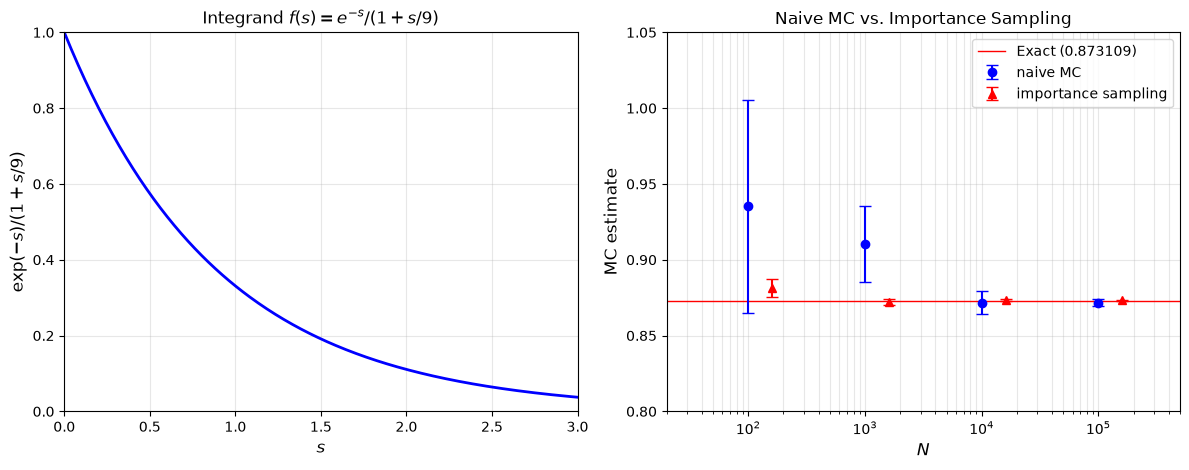

In [34]:
# =====================================================================
# Importance Sampling for a Sharply Peaked Integrand
# =====================================================================

rng = np.random.default_rng(52)
b = 3.0
exact_val = 0.873109

# 1. Define the integrand f(s), sampling density p_Y(s), and inverse CDF F_Y^{-1}(u)
def f(s):
    return np.exp(-s) / (1.0 + s / 9.0)

def p_Y(s, b=3.0):
    return np.exp(-s) / (1.0 - np.exp(-b))

def inv_cdf(u, b=3.0):
    """Inverse Transform: F_Y^{-1}(u) = -ln(1 - (1 - e^{-b})u)"""
    return -np.log(1.0 - (1.0 - np.exp(-b)) * u)

# 2. Run Naive MC and Importance Sampling 
N_list = [10**1, 10**2, 10**3, 10**4, 10**5]
naive_ests, naive_errs = [], []
imp_ests, imp_errs = [], []

print(f"{'N':>7} | {'Naive MC ± Error':>22} | {'Importance Sampling ± Error':>28}")
print("-" * 65)

for N in N_list:
    # --- Naive Uniform MC ---
    s_unif = rng.uniform(0.0, b, N)
    vals_naive = b * f(s_unif)
    est_n = np.mean(vals_naive)
    err_n = np.sqrt((np.mean(vals_naive**2) - est_n**2) / N)
    naive_ests.append(est_n)
    naive_errs.append(err_n)
    
    # --- Importance Sampling via Transformation Method ---
    u = rng.uniform(0.0, 1.0, N)
    s_imp = inv_cdf(u, b=b)
    vals_imp = f(s_imp) / p_Y(s_imp, b=b)
    est_i = np.mean(vals_imp)
    err_i = np.sqrt((np.mean(vals_imp**2) - est_i**2) / N)
    imp_ests.append(est_i)
    imp_errs.append(err_i)
    
    print(f"{N:7d} | {est_n:9.6f} ± {err_n:9.6f} | {est_i:12.6f} ± {err_i:9.6f}")

# 3. Reproduce Fig. 6 from the article
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Left Panel: Plot of the integrand e^{-s} / (1 + s/9)
s_grid = np.linspace(0, b, 300)
ax1.plot(s_grid, f(s_grid), 'b-', lw=2)
ax1.set_xlim(0, 3)
ax1.set_ylim(0, 1)
ax1.set_xlabel('$s$', fontsize=12)
ax1.set_ylabel(r'$\exp(-s)/(1 + s/9)$', fontsize=12)
ax1.set_title('Integrand $f(s) = e^{-s}/(1 + s/9)$')
ax1.grid(True, alpha=0.3)

# Right Panel: MC Estimates with Error Bars vs N
N_arr = np.array(N_list, dtype=float)
ax2.axhline(exact_val, color='red', lw=1, label='Exact (0.873109)')
ax2.errorbar(N_arr, naive_ests, yerr=naive_errs, fmt='bo', capsize=4, label='naive MC')
# Offset importance sampling x-positions slightly (N * 1.6) just like Fig. 6 so error bars don't overlap
ax2.errorbar(N_arr * 1.6, imp_ests, yerr=imp_errs, fmt='r^', capsize=4, label='importance sampling')

ax2.set_xscale('log')
ax2.set_xlim(20, 5e5)
ax2.set_ylim(0.8, 1.05)
ax2.set_xlabel('$N$', fontsize=12)
ax2.set_ylabel('MC estimate', fontsize=12)
ax2.set_title('Naive MC vs. Importance Sampling')
ax2.legend()
ax2.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

## The Rejection Method (von Neumann Acceptance-Rejection Sampling)

When a target probability density $p_X(x)$ on $a \le x \le b$ cannot be easily integrated and inverted analytically, we use the **Rejection Method**.

**Core Principle:** Sampling $x$ from a 1D density $p_X(x)$ is equivalent to sampling a 2D point $(x, y)$ uniformly within the **area under the curve** $y = p_X(x)$ and keeping its $x$-coordinate.

#### 1. Simple Box Rejection (Uniform Envelope)
1. Enclose $p_X(x)$ in a bounding box of width $[a, b]$ and height $M = \max(p_X(x))$.
2. Generate uniform coordinates:
   $$x \sim \text{Uniform}(a, b), \qquad y \sim \text{Uniform}\left(0, \max(p_X(x))\right)$$
3. **Acceptance Criterion:**
   * If $y \le p_X(x)$ (point lies below the curve), **accept** $x$.
   * If $y > p_X(x)$ (point lies above the curve), **reject** $x$ and repeat.
* **Efficiency (Acceptance Probability):** $\text{Efficiency} = \frac{\text{Area under} \, \, p_X(x)}{\text{Area of box}} = \frac{\int_a^b p_X(x)\,dx}{(b - a)\max(p_X(x))}$.

#### 2. General Rejection with a Comparison Function $f(x) \ge p_X(x)$
If $p_X(x)$ is sharply peaked, a rectangular box wastes most samples in the empty region above the tails. Instead, choose a **comparison (envelope) function** $f(x)$ such that:
$$f(x) \ge p_X(x) \quad \forall \, \, x \in [a, b]$$
where $f(x)$ has an invertible cumulative distribution and can be sampled via the **Transformation Method**:
1. Sample candidate $x$ from the normalized density $q(x) = \frac{f(x)}{\int_a^b f(s)\,ds}$ using $x = F_q^{-1}(u_1)$ with $u_1 \sim \text{Uniform}(0, 1)$.
2. Sample a vertical height uniformly under the comparison curve at $x$:
   $$y \sim \text{Uniform}(0, f(x)) \quad \Longleftrightarrow \quad y = u_2 \cdot f(x), \quad u_2 \sim \text{Uniform}(0, 1)$$
3. **Accept** $x$ if $y \le p_X(x)$; otherwise reject and repeat.
* **Efficiency:** $\frac{\int_a^b p_X(x)\,dx}{\int_a^b f(x)\,ds}$, which approaches $100\%$ the closer $f(x)$ hugs $p_X(x)$.

[ True  True  True ...  True  True  True]
--- Part 1: Double-Peak Box Rejection ---
Total trials: 5000 | Accepted: 3647 | Acceptance Rate: 72.9%

--- Part 2: Peaked Function (Box vs. Comparison Function f(x)) ---
Box Rejection Acceptance Rate        : 22.0%
Comparison f(x) Acceptance Rate      : 84.6% (3.8x more efficient!)


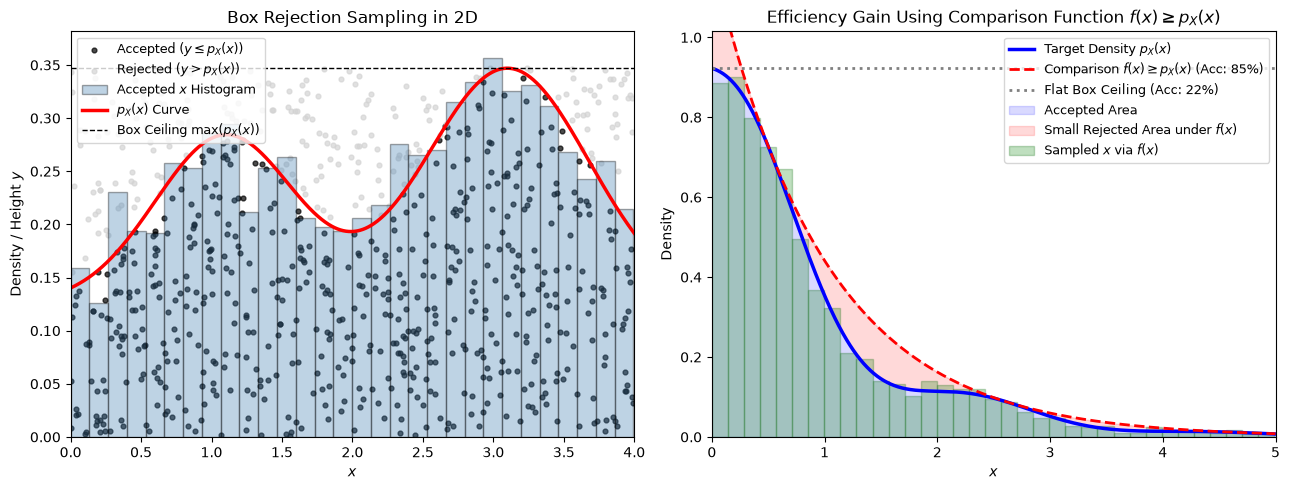

In [ ]:
from scipy.integrate import quad
rng = np.random.default_rng(52)

# =====================================================================
# Part 1: Visualizing 2D Box Rejection (Two-Peak Curve like the Article)
# Target unnormalized shape on [0, 4], normalized numerically for plotting
# =====================================================================

a, b = 0.0, 4.0
raw_p1 = lambda x: 0.4 + 0.5 * np.exp(-2.0 * (x - 1.1)**2) + 0.7 * np.exp(-1.5 * (x - 3.1)**2) # Unnormalized target density
norm_1, _ = quad(raw_p1, a, b)
p_X1 = lambda x: raw_p1(x) / norm_1

# Find max(p_X(x)) on [a, b]
x_grid1 = np.linspace(a, b, 1000)
M1 = np.max(p_X1(x_grid1))

# Throw N_trials 2D uniform darts in the box [a, b] x [0, M1]
N_trials = 5_000
x_cand = rng.uniform(a, b, N_trials)
y_cand = rng.uniform(0.0, M1, N_trials)

accepted_mask = y_cand <= p_X1(x_cand)
x_accepted = x_cand[accepted_mask]

print("--- Part 1: Double-Peak Box Rejection ---")
print(f"Total trials: {N_trials} | Accepted: {np.sum(accepted_mask)} | Acceptance Rate: {np.mean(accepted_mask)*100:.1f}%\n")

# =====================================================================
# Part 2: Sharply Peaked p_X(x) — Box vs. Comparison Function f(x)
# Target density on [0, 5]: p_X(x) = C * e^{-x} * (1 + 0.3 * sin(3x))
# Its CDF is tedious to invert, so we use Rejection Sampling!
# =====================================================================
a2, b2 = 0.0, 5.0
raw_p2 = lambda x: np.exp(-x) * (1.0 + 0.3 * np.sin(3.0 * x)) # Unnormalized target density
norm_2, _ = quad(raw_p2, a2, b2)
p_X2 = lambda x: raw_p2(x) / norm_2

x_grid2 = np.linspace(a2, b2, 1000)
M2 = np.max(p_X2(x_grid2))

# --- Method A: Simple Box Rejection on [0, 5] x [0, M2] ---
x_box = rng.uniform(a2, b2, N_trials)
y_box = rng.uniform(0.0, M2, N_trials)
acc_box = x_box[y_box <= p_X2(x_box)]
eff_box = len(acc_box) / N_trials # Acceptance efficiency for box rejection

# --- Method B: Comparison Function f(x) >= p_X(x) via Transformation Method ---
# Since (1 + 0.3*sin(3x)) <= 1.3 everywhere, we bound p_X(x) from above with:
# f(x) = (1.3 / norm_2) * e^{-x} >= p_X(x) for all x in [0, 5]
f_comp = lambda x: (1.3 / norm_2) * np.exp(-x)

# Sample x from the normalized exponential density proportional to e^{-x} on [0, 5]
# using the exact Inverse Transform formula from the previous section!
u1 = rng.uniform(0.0, 1.0, N_trials)
x_comp = -np.log(1.0 - (1.0 - np.exp(-b2)) * u1) # Inverse CDF of truncated exponential on [0, 5]

# Sample y uniformly in [0, f(x)] and accept if y <= p_X(x)
y_comp = rng.uniform(0.0, 1.0, N_trials) * f_comp(x_comp) # Sample y uniformly in [0, f(x)]
acc_comp = x_comp[y_comp <= p_X2(x_comp)] # Accepted x values using comparison function rejection
eff_comp = len(acc_comp) / N_trials # Acceptance efficiency for comparison function rejection

print("--- Part 2: Peaked Function (Box vs. Comparison Function f(x)) ---")
print(f"Box Rejection Acceptance Rate        : {eff_box*100:.1f}%")
print(f"Comparison f(x) Acceptance Rate      : {eff_comp*100:.1f}% ({eff_comp/eff_box:.1f}x more efficient!)")

# =====================================================================
# Visualization
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left Plot: 2D Dartboard & Histogram for Part 1 (show first 800 darts for clarity)
n_show = 800
ax1.scatter(x_cand[:n_show][accepted_mask[:n_show]], y_cand[:n_show][accepted_mask[:n_show]],
            color='black', s=12, alpha=0.7, label=rf'Accepted ($y \leq p_X(x)$)')
ax1.scatter(x_cand[:n_show][~accepted_mask[:n_show]], y_cand[:n_show][~accepted_mask[:n_show]],
            color='lightgray', s=12, alpha=0.7, label=rf'Rejected ($y > p_X(x)$)')
ax1.hist(x_accepted, bins=30, density=True, color='steelblue', alpha=0.35, edgecolor='black', label='Accepted $x$ Histogram')
ax1.plot(x_grid1, p_X1(x_grid1), 'r-', lw=2.5, label='$p_X(x)$ Curve')
ax1.axhline(M1, color='k', ls='--', lw=1, label=r'Box Ceiling $\max(p_X(x))$')
ax1.set_xlim(a, b)
ax1.set_ylim(0, M1 * 1.1)
ax1.set_xlabel('$x$')
ax1.set_ylabel('Density / Height $y$')
ax1.set_title('Box Rejection Sampling in 2D')
ax1.legend(loc='upper left', fontsize=9)

# Right Plot: Peaked p_X(x) with Box Ceiling vs. Comparison Function f(x)
ax2.plot(x_grid2, p_X2(x_grid2), 'b-', lw=2.5, label='Target Density $p_X(x)$')
ax2.plot(x_grid2, f_comp(x_grid2), 'r--', lw=2, label=rf'Comparison $f(x) \geq p_X(x)$ (Acc: {eff_comp*100:.0f}%)')
ax2.axhline(M2, color='gray', ls=':', lw=2, label=rf'Flat Box Ceiling (Acc: {eff_box*100:.0f}%)')
ax2.fill_between(x_grid2, 0, p_X2(x_grid2), color='blue', alpha=0.15, label=rf'Accepted Area')
ax2.fill_between(x_grid2, p_X2(x_grid2), f_comp(x_grid2), color='red', alpha=0.15, label=rf'Small Rejected Area under $f(x)$')
ax2.hist(acc_comp, bins=35, density=True, color='green', alpha=0.25, edgecolor='darkgreen', label=rf'Sampled $x$ via $f(x)$')
ax2.set_xlim(a2, b2)
ax2.set_ylim(0, M2 * 1.1)
ax2.set_xlabel('$x$')
ax2.set_ylabel('Density')
ax2.set_title(r'Efficiency Gain Using Comparison Function $f(x) \geq p_X(x)$')
ax2.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

### Importance Sampling via the Rejection Method vs. Naive Monte Carlo

When evaluating $I = \int_a^b f(x)\,dx$, if we choose an importance sampling probability density $g(x)$ ($\int_a^b g(x)\,dx = 1$) whose cumulative distribution is not easily invertible, we use the **Rejection Method** to generate the $N$ sample points $x_1, \dots, x_N \sim g(x)$:

1. **Generate Samples $x_j \sim g(x)$ via Rejection Sampling:**
   Pick uniform points $(x, y)$ in the bounding box $[a, b] \times [0, \max(g(x))]$ and accept $x$ if $y \le g(x)$ until $N$ samples $x_1, \dots, x_N$ are collected.

2. **Importance Sampling Estimator:**
   Evaluate the flattened ratio $h(x_j) = \frac{f(x_j)}{g(x_j)}$ at the accepted points:
   $$I_{\text{IS}} = \int_a^b \frac{f(x)}{g(x)} g(x)\,dx \approx \langle h \rangle \pm \sqrt{\frac{\langle h^2 \rangle - \langle h \rangle^2}{N}}, \qquad \langle h \rangle = \frac{1}{N}\sum_{j=1}^N \frac{f(x_j)}{g(x_j)}$$

3. **Naive Monte Carlo Estimator:**
   Sample $x_1, \dots, x_N \sim \text{Uniform}(a, b)$ and compute:
   $$I_{\text{naive}} \approx (b - a)\langle f \rangle \pm (b - a)\sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$$

Exact Integral Value: 0.382714

      N |       Naive MC ± Error |  Importance Sampling ± Error
-----------------------------------------------------------------
    100 |  0.391968 ±  0.029578 |     0.383409 ±  0.002248
   1000 |  0.391065 ±  0.009636 |     0.383083 ±  0.000722
  10000 |  0.380404 ±  0.002981 |     0.382922 ±  0.000220
 100000 |  0.382400 ±  0.000939 |     0.382757 ±  0.000069


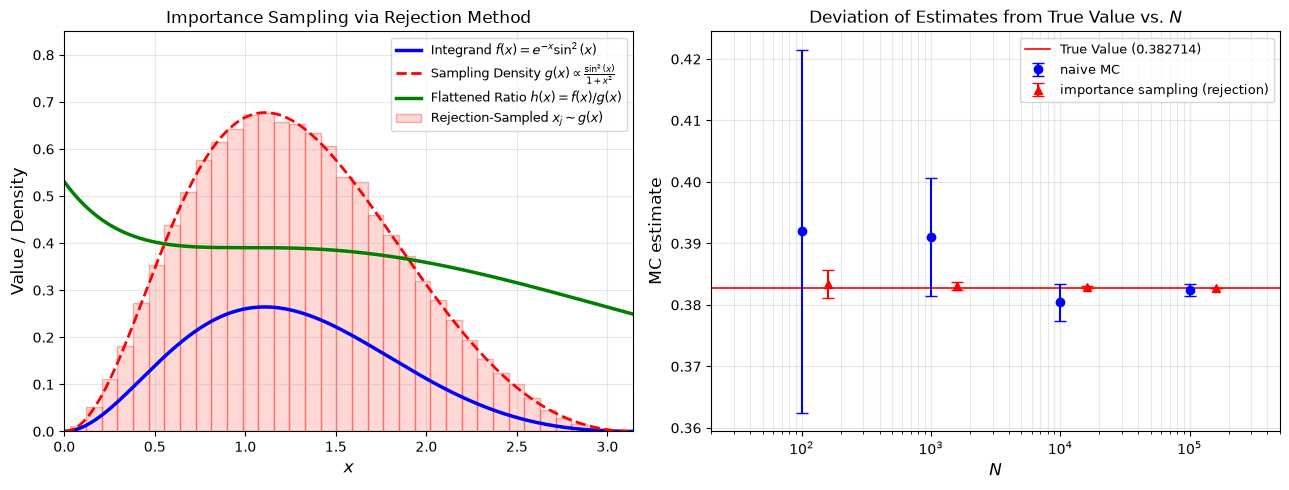

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

rng = np.random.default_rng(7)

# =====================================================================
# Target Integral: I = \int_0^\pi e^{-x} * sin^2(x) dx
# Exact Analytical Value: 2 * (1 - e^{-\pi}) / 5 ≈ 0.38271447
# =====================================================================
a, b = 0.0, np.pi

def f(x):
    """Integrand f(x) on [0, pi]."""
    return np.exp(-x) * (np.sin(x) ** 2)

exact_val = 2.0 * (1.0 - np.exp(-np.pi)) / 5.0

# ---------------------------------------------------------------------
# Importance Sampling Density g(x) Sampled via the Rejection Method
# Choose g(x) proportional to sin^2(x) / (1 + x^2) on [0, pi].
# It never hits zero where e^{-x} > 0, so h(x) = f(x)/g(x) never blows up!
# ---------------------------------------------------------------------
g_norm, _ = quad(lambda x: (np.sin(x) ** 2) / (1.0 + x**2), a, b)

def g_pdf(x):
    """Normalized importance density g(x) on [0, pi]."""
    return (np.sin(x) ** 2) / ((1.0 + x**2) * g_norm)

def h_ratio(x):
    """Flattened function h(x) = f(x) / g(x) = g_norm * e^{-x} * (1 + x^2)."""
    return g_norm * np.exp(-x) * (1.0 + x**2)

def sample_g_rejection(g_pdf, a, b, g_max, N, rng):
    """Draws N samples from g_pdf(x) using the 2D Box Rejection Method."""
    accepted = []
    while len(accepted) < N:
        batch_size = int((N - len(accepted)) * 2.5) + 100
        x_try = rng.uniform(a, b, batch_size)
        y_try = rng.uniform(0.0, g_max, batch_size)
        keep = x_try[y_try <= g_pdf(x_try)]
        accepted.extend(keep)
    return np.array(accepted[:N])

# ---------------------------------------------------------------------
# Integration Functions: Naive MC vs. Importance Sampling (Rejection)
# ---------------------------------------------------------------------
def integrate_naive_mc(f, a, b, N, rng):
    x = rng.uniform(a, b, N)
    vals = (b - a) * f(x)
    est = np.mean(vals)
    err = np.sqrt((np.mean(vals**2) - est**2) / N)
    return est, err

def integrate_importance_rejection(a, b, g_max, N, rng):
    x_imp = sample_g_rejection(g_pdf, a, b, g_max, N, rng)
    h_vals = h_ratio(x_imp)
    est = np.mean(h_vals)
    err = np.sqrt((np.mean(h_vals**2) - est**2) / N)
    return est, err, x_imp

# =====================================================================
# Run Both Methods Across N = 10^2, 10^3, 10^4, 10^5
# =====================================================================
x_grid = np.linspace(a, b, 500)
g_max = np.max(g_pdf(x_grid)) * 1.02

N_list = [10**2, 10**3, 10**4, 10**5]
naive_ests, naive_errs = [], []
imp_ests, imp_errs = [], []

print(f"Exact Integral Value: {exact_val:.6f}\n")
print(f"{'N':>7} | {'Naive MC ± Error':>22} | {'Importance Sampling ± Error':>28}")
print("-" * 65)

for N in N_list:
    est_n, err_n = integrate_naive_mc(f, a, b, N, rng)
    est_i, err_i, x_imp_last = integrate_importance_rejection(a, b, g_max, N, rng)
    
    naive_ests.append(est_n)
    naive_errs.append(err_n)
    imp_ests.append(est_i)
    imp_errs.append(err_i)
    
    print(f"{N:7d} | {est_n:9.6f} ± {err_n:9.6f} | {est_i:12.6f} ± {err_i:9.6f}")

# =====================================================================
# Plotting:
# Left Plot : Integrand f(x), Rejection-Sampled g(x), and Flattened h(x)
# Right Plot: How Estimates Deviate from the True Value vs. N
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --- Left Panel: Importance Sampling Visualization ---
ax1.plot(x_grid, f(x_grid), 'b-', lw=2.5, label=r'Integrand $f(x) = e^{-x}\sin^2(x)$')
ax1.plot(x_grid, g_pdf(x_grid), 'r--', lw=2, label=r'Sampling Density $g(x) \propto \frac{\sin^2(x)}{1+x^2}$')
ax1.plot(x_grid, h_ratio(x_grid), 'g-', lw=2.5, label=r'Flattened Ratio $h(x) = f(x)/g(x)$')
ax1.hist(x_imp_last, bins=35, density=True, color='salmon', alpha=0.3, edgecolor='red',
         label=r'Rejection-Sampled $x_j \sim g(x)$')
ax1.set_xlim(a, b)
ax1.set_ylim(0, 0.85)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('Value / Density', fontsize=12)
ax1.set_title('Importance Sampling via Rejection Method')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)

# --- Right Panel: Estimates & Deviation from True Value vs. N ---
N_arr = np.array(N_list, dtype=float)
ax2.axhline(exact_val, color='red', lw=1.2, label=f'True Value ({exact_val:.6f})')
ax2.errorbar(N_arr, naive_ests, yerr=naive_errs, fmt='bo', capsize=4, label='naive MC')
ax2.errorbar(N_arr * 1.6, imp_ests, yerr=imp_errs, fmt='r^', capsize=4, label='importance sampling (rejection)')

ax2.set_xscale('log')
ax2.set_xlim(20, 5e5)
ax2.set_xlabel('$N$', fontsize=12)
ax2.set_ylabel('MC estimate', fontsize=12)
ax2.set_title('Deviation of Estimates from True Value vs. $N$')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()